### Loading scGPT on test data

In [1]:
import sys
import platform
import numpy as np
import pandas as pd
import scipy
import scanpy as sc

print("Python:", sys.version)
print("Executable:", sys.executable)
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scanpy:", sc.__version__)

Python: 3.10.13 (main, Sep 19 2023, 15:54:50) [GCC 12.3.1 20230526]
Executable: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
Platform: Linux-5.14.0-570.44.1.el9_6.x86_64-x86_64-Intel-R-_Xeon-R-_6972P-with-glibc2.37
NumPy: 1.26.4
Pandas: 2.3.3
SciPy: 1.12.0
Scanpy: 1.10.4


In [2]:
from pathlib import Path

import anndata as ad
import pandas as pd
from scipy import sparse
from scipy.io import mmread

DATA_DIR = Path(
    "/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/"
    "benchmarking_spatial_scale/GDC-data/"
    "C3N-00148/C3N-00148-01/single_cell/"
    "dbe28c52-cdbf-477e-a728-9a61fd4a8139/"
    "qc_filtered_bc_feature_matrix"
)

features = pd.read_csv(
    DATA_DIR / "features.tsv",
    sep="\t",
    header=None,
    names=["gene_id", "gene_symbol", "feature_type"],
    dtype=str,
)

barcodes = pd.read_csv(
    DATA_DIR / "barcodes.tsv",
    sep="\t",
    header=None,
    names=["barcode"],
    dtype=str,
)

# Matrix Market file is genes × cells.
# AnnData convention is cells × genes, so transpose it.
counts = mmread(DATA_DIR / "matrix.mtx").T.tocsr()

assert sparse.issparse(counts)
assert counts.shape == (len(barcodes), len(features))

adata = ad.AnnData(X=counts)

adata.obs_names = barcodes["barcode"].to_numpy()
adata.var_names = features["gene_symbol"].to_numpy()

adata.var["gene_id"] = features["gene_id"].to_numpy()
adata.var["feature_type"] = features["feature_type"].to_numpy()

# Some gene symbols may be duplicated.
adata.var_names_make_unique()

/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/anndata/utils.py:261: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`Example key collisions generated by the make_index_unique algorithm: ['SNORD116-1', 'SNORD116-2', 'SNORD116-3', 'SNORD116-4', 'SNORD116-5']
  warnings.warn(


In [3]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy import sparse
from scgpt.tasks import embed_data

print("Python environment:")
import sys
print(sys.executable)

torch.set_num_threads(2)
torch.manual_seed(42)
np.random.seed(42)

MODEL_DIR = Path.home() / "scgpt-cna/models/whole-human"

for filename in ["args.json", "vocab.json", "best_model.pt"]:
    assert (MODEL_DIR / filename).is_file(), f"Missing: {filename}"

/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Python environment:
/home/akash1/scgpt-cna/.venv-scgpt/bin/python


In [4]:
if "counts" not in adata.layers:
    adata.layers["counts"] = adata.X.copy()

features = pd.read_csv(
    DATA_DIR / "features.tsv",
    sep="\t",
    header=None,
    dtype=str,
)

symbol_by_id = features.set_index(0)[1]
assert symbol_by_id.index.is_unique

adata.var["gene_symbol"] = adata.var["gene_id"].map(symbol_by_id)
assert adata.var["gene_symbol"].notna().all()



with open(MODEL_DIR / "vocab.json") as f:
    vocab = json.load(f)

gene_match = adata.var["gene_symbol"].isin(vocab)
print(f"Genes in vocabulary: {gene_match.sum():,}/{adata.n_vars:,}")

rng = np.random.default_rng(42)
cell_indices = rng.choice(adata.n_obs, size=16, replace=False)

test = adata[cell_indices, gene_match].copy()
test.X = test.layers["counts"].copy()

# For this first test, retain the first occurrence of duplicate symbols.
# We can decide a principled aggregation policy later.
unique_symbols = ~test.var["gene_symbol"].duplicated()
test = test[:, unique_symbols].copy()

nonempty_cells = np.asarray(test.X.sum(axis=1)).ravel() > 0
test = test[nonempty_cells].copy()

assert test.n_obs > 0 and test.n_vars > 0

# Only this tiny subset becomes dense.
test.X = (
    test.X.toarray() if sparse.issparse(test.X) else np.asarray(test.X)
).astype(np.float32)

print(test)
print("Input matrix memory:", round(test.X.nbytes / 1024**2, 2), "MiB")

Genes in vocabulary: 39,839/60,660
AnnData object with n_obs × n_vars = 16 × 39800
    var: 'gene_id', 'feature_type', 'gene_symbol'
    layers: 'counts'
Input matrix memory: 2.43 MiB


In [5]:
result = embed_data(
    test,
    model_dir=MODEL_DIR,
    gene_col="gene_symbol",
    max_length=1200,
    batch_size=1,
    device="cpu",
    use_fast_transformer=False,
    return_new_adata=False,
)

embeddings = result.obsm["X_scGPT"]

print("Output shape:", embeddings.shape)
print("All values finite:", np.isfinite(embeddings).all())
print("First cell, first 10 values:")
print(embeddings[0, :10])

scGPT - INFO - match 39800/39800 genes in vocabulary of size 60697.


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/torch/amp/autocast_mode.py:250: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(
Embedding cells:   0%|          | 0/16 [00:00<?, ?it/s]/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/torch/nn/modules/transformer.py:384: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. (Triggered internally at ../aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(output, src_key_padding_mask.logical_not(), mask_check=False)
Embedding cells: 100%|██████████| 16/16 [00:19<00:00,  1.20s/it]

Output shape: (16, 512)
All values finite: True
First cell, first 10 values:
[ 0.00808057  0.04085669  0.0194615  -0.03374953  0.0008361  -0.01150952
 -0.02848678 -0.01074738  0.01093716 -0.01316252]



/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/tasks/cell_emb.py:279: ImplicitModificationWarning: Setting element `.obsm['X_scGPT']` of view, initializing view as actual.
  adata.obsm["X_scGPT"] = cell_embeddings


### Investigating metadata directory

In [6]:
META="/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale/metadata/sample_md.tsv"

In [7]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    "/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/"
    "benchmarking_spatial_scale"
)

metadata_path = PROJECT_ROOT / "metadata/sample_md.tsv"

md = pd.read_csv(
    metadata_path,
    sep="\t",
    dtype=str,
    keep_default_na=False,
)

print("Rows × columns:", md.shape)
print("Columns:", md.columns.tolist())
display(md.head())

Rows × columns: (35, 12)
Columns: ['sample_id', 'case_id', 'demographic.days_to_death', 'demographic.ethnicity', 'demographic.gender', 'demographic.race', 'demographic.vital_status', 'diagnoses.0.age_at_diagnosis', 'diagnoses.0.primary_diagnosis', 'disease_type', 'primary_site', 'wgd_status']


,sample_id,case_id,demographic.days_to_death,demographic.ethnicity,demographic.gender,demographic.race,demographic.vital_status,diagnoses.0.age_at_diagnosis,diagnoses.0.primary_diagnosis,disease_type,primary_site,wgd_status
0,C3L-00359-01,C3L-00359,1779,not hispanic or latino,female,white,Dead,26864,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD+
1,C3L-00606-01,C3L-00606,1045,not hispanic or latino,female,white,Dead,27636,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD+
2,C3L-00606-02,C3L-00606,1045,not hispanic or latino,female,white,Dead,27636,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD+
3,C3L-00606-03,C3L-00606,1045,not hispanic or latino,female,white,Dead,27636,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD+
4,C3L-01287-01,C3L-01287,633,not hispanic or latino,male,white,Dead,22045,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD-


In [8]:
case_match = md.apply(
    lambda column: column.str.contains("C3N-00148", regex=False)
).any(axis=1)

sample_match = md.apply(
    lambda column: column.str.contains("C3N-00148-01", regex=False)
).any(axis=1)

print("Rows mentioning case:", int(case_match.sum()))
print("Rows mentioning sample:", int(sample_match.sum()))

with pd.option_context("display.max_columns", None):
    display(md.loc[case_match].head(20))

Rows mentioning case: 4
Rows mentioning sample: 1


,sample_id,case_id,demographic.days_to_death,demographic.ethnicity,demographic.gender,demographic.race,demographic.vital_status,diagnoses.0.age_at_diagnosis,diagnoses.0.primary_diagnosis,disease_type,primary_site,wgd_status
11,C3N-00148-01,C3N-00148,NA,not reported,male,white,Alive,19314,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD+
12,C3N-00148-02,C3N-00148,NA,not reported,male,white,Alive,19314,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD-
13,C3N-00148-03,C3N-00148,NA,not reported,male,white,Alive,19314,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD-
14,C3N-00148-04,C3N-00148,NA,not reported,male,white,Alive,19314,"Renal cell carcinoma, NOS",Adenomas and Adenocarcinomas,Kidney,WGD-


In [9]:
copykat_dir = DATA_DIR.parent / "copykatOUT"
prediction_path = copykat_dir / "_copykat_prediction.txt"

assert prediction_path.is_file(), prediction_path

ck = pd.read_csv(
    prediction_path,
    sep="\t",
    dtype=str,
    keep_default_na=False,
)

print("Shape:", ck.shape)
print("Columns:", ck.columns.tolist())
display(ck.head())

Shape: (7584, 2)
Columns: ['cell.names', 'copykat.pred']


,cell.names,copykat.pred
0,AAACCCAAGAAGTGTT-1,diploid
1,AAACCCAAGCCTGTCG-1,diploid
2,AAACCCAAGCGCTGCT-1,diploid
3,AAACCCAAGTTCCGGC-1,aneuploid
4,AAACCCACAAGCGCTC-1,diploid


In [10]:
predictions = ck.set_index("cell.names")["copykat.pred"]

adata.obs["copykat_prediction"] = (
    predictions.reindex(adata.obs_names).to_numpy()
)

matched = adata.obs["copykat_prediction"].notna()

print(f"Matched cells: {matched.sum():,}/{adata.n_obs:,}")
print("CopyKAT barcodes absent from adata:",
      len(predictions.index.difference(adata.obs_names)))

display(
    adata.obs["copykat_prediction"]
    .fillna("missing_from_output")
    .value_counts()
)

Matched cells: 7,584/7,598
CopyKAT barcodes absent from adata: 0


copykat_prediction
aneuploid              4106
diploid                2100
not.defined            1378
missing_from_output      14
Name: count, dtype: int64

In [11]:
import numpy as np
from scipy import sparse

# This assumes X is still raw counts if no counts layer exists.
raw_counts = adata.layers.get("counts", adata.X)

adata.obs["total_counts"] = np.asarray(
    raw_counts.sum(axis=1)
).ravel()

adata.obs["n_genes_detected"] = (
    np.asarray((raw_counts > 0).sum(axis=1)).ravel()
    if sparse.issparse(raw_counts)
    else np.count_nonzero(raw_counts > 0, axis=1)
)

group = adata.obs["copykat_prediction"].fillna("missing_from_output")

qc = adata.obs[["total_counts", "n_genes_detected"]].copy()
qc["copykat_group"] = group

display(
    qc.groupby("copykat_group")
      .agg(["count", "median", "min", "max"])
)

display(qc.loc[group.eq("missing_from_output")])

total_counts                     n_genes_detected          \
                           count  median  min    max            count  median   
copykat_group                                                                   
aneuploid                   4106  3367.0  778  19863             4106  1818.0   
diploid                     2100  2916.0  647  24279             2100  1590.0   
missing_from_output           14  1556.5  954   2833               14   136.5   
not.defined                 1378  1456.0  500  14529             1378   876.5   

                                
                     min   max  
copykat_group                   
aneuploid            596  5513  
diploid              473  6980  
missing_from_output   64   169  
not.defined          209  4243

,total_counts,n_genes_detected,copykat_group
AACGGGAAGAGAGCAA-1,2655,64,missing_from_output
ATGAAAGCAAAGGCGT-1,2785,154,missing_from_output
CAATTTCTCGCACTCT-1,1196,152,missing_from_output
CCACACTTCATTTACC-1,2833,169,missing_from_output
CCGATCTGTATACGGG-1,1208,110,missing_from_output
CCGCAAGGTCACCGAC-1,954,139,missing_from_output
GGCACGTAGGACTTCT-1,1744,134,missing_from_output
GGGACAAAGCCGATAG-1,1076,67,missing_from_output
GGGACAAGTCGAAGCA-1,1076,97,missing_from_output
GGGTTTAAGCCGTAAG-1,1185,168,missing_from_output


In [12]:
print("Unique sample IDs:", md["sample_id"].nunique())
print("Unique case IDs:", md["case_id"].nunique())
print("Repeated sample IDs:", md["sample_id"].duplicated().sum())

display(
    md.groupby(
        ["primary_site", "diagnoses.0.primary_diagnosis", "wgd_status"]
    ).size().rename("n_samples").reset_index()
)

Unique sample IDs: 35
Unique case IDs: 27
Repeated sample IDs: 0


,primary_site,diagnoses.0.primary_diagnosis,wgd_status,n_samples
0,Brain,Glioblastoma,WGD+,8
1,Brain,Glioblastoma,WGD-,8
2,Kidney,Angiomyolipoma,WGD-,2
3,Kidney,Oncocytoma,WGD-,2
4,Kidney,Papillary renal cell carcinoma,WGD-,1
5,Kidney,"Renal cell carcinoma, NOS",WGD+,8
6,Kidney,"Renal cell carcinoma, NOS",WGD-,6


In [13]:
from pathlib import Path
import pandas as pd

positions = pd.read_csv(
    Path.home() / "scgpt-cna/reference/gene_positions.tsv",
    sep="\t",
    dtype={"seqnames": str, "gene_id": str, "gene_name": str},
)

# Keep the original versioned IDs; make a separate matching key.
gene_ids_base = adata.var["gene_id"].str.replace(
    r"\.\d+$", "", regex=True
)

has_position = gene_ids_base.isin(positions["gene_id"])

print("Genes in coordinate table:", len(positions))
print("Expression features with coordinates:", int(has_position.sum()))

if "gene_symbol" in adata.var:
    in_vocab = adata.var["gene_symbol"].isin(vocab)
    print(
        "Features with coordinates AND in scGPT vocabulary:",
        int((has_position & in_vocab).sum()),
    )

display(positions.head())

Genes in coordinate table: 7237
Expression features with coordinates: 7183
Features with coordinates AND in scGPT vocabulary: 7152


,seqnames,start,end,gene_id,gene_name
0,1,633696,634376,ENSG00000248527,MTATP6P1
1,1,944204,959309,ENSG00000188976,NOC2L
2,1,998962,1000172,ENSG00000188290,HES4
3,1,1020123,1056118,ENSG00000188157,AGRN
4,1,1081818,1116361,ENSG00000131591,C1orf159


In [14]:
expression_ids = set(gene_ids_base.dropna())
coordinate_ids = set(positions["gene_id"].dropna())

print("Unique shared gene IDs:", len(expression_ids & coordinate_ids))
print("Coordinate IDs absent from expression:",
      len(coordinate_ids - expression_ids))

Unique shared gene IDs: 7183
Coordinate IDs absent from expression: 54


## scGPT inference experiments

### Take 1

In [15]:
from pathlib import Path
import json
import gc

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from scipy import sparse
from scgpt.model import TransformerModel
from scgpt.tokenizer import GeneVocab
from scgpt.preprocess import _digitize

SEED = 42
N_EVAL_PER_GROUP = 16
N_REF_PER_GROUP = 64
N_REPEATS = 2
MAX_GENES = 1199       # Plus one <cls> token
MASK_FRACTION = 0.15
N_BINS = 51            # Zero plus positive bins 1–50

MODEL_DIR = Path.home() / "scgpt-cna/models/whole-human"

torch.set_num_threads(4)
torch.manual_seed(SEED)

assert "copykat_prediction" in adata.obs
assert "counts" in adata.layers, "Run raw-count preservation first."

print("Cells:", adata.n_obs)
print("Raw-count matrix:", adata.layers["counts"].shape)

Cells: 7598
Raw-count matrix: (7598, 60660)


In [16]:
with open(MODEL_DIR / "args.json") as f:
    config = json.load(f)

print("Checkpoint configuration:")
print(config)

if "n_bins" in config:
    assert int(config["n_bins"]) == N_BINS, "Check bin configuration."

vocab = GeneVocab.from_file(MODEL_DIR / "vocab.json")

for token in ["<pad>", "<cls>", "<eoc>"]:
    if token not in vocab:
        vocab.append_token(token)

PAD_VALUE = float(config.get("pad_value", -2))
MASK_VALUE = -1.0

model = TransformerModel(
    ntoken=len(vocab),
    d_model=config["embsize"],
    nhead=config["nheads"],
    d_hid=config["d_hid"],
    nlayers=config["nlayers"],
    nlayers_cls=config.get("n_layers_cls", 3),
    n_cls=1,
    vocab=vocab,
    dropout=config.get("dropout", 0.2),
    pad_token=config.get("pad_token", "<pad>"),
    pad_value=PAD_VALUE,
    input_emb_style="continuous",
    do_mvc=False,
    do_dab=False,
    use_batch_labels=False,
    domain_spec_batchnorm=False,
    explicit_zero_prob=False,
    use_fast_transformer=False,
    pre_norm=False,
)

checkpoint = torch.load(
    MODEL_DIR / "best_model.pt",
    map_location="cpu",
)

# Handle common checkpoint wrappers.
if "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

# Same FlashAttention → standard PyTorch name conversion used
# by scGPT's official loading utility.
weights = {
    key.removeprefix("module.").replace("Wqkv.", "in_proj_"): value
    for key, value in checkpoint.items()
}

expected = model.state_dict()

# Classification weights are irrelevant to this experiment.
required = [
    key for key in expected
    if not key.startswith("cls_decoder.")
]

missing = [key for key in required if key not in weights]
wrong_shape = [
    key for key in required
    if key in weights and weights[key].shape != expected[key].shape
]

assert not missing, f"Missing prediction/backbone weights: {missing[:10]}"
assert not wrong_shape, f"Incompatible weights: {wrong_shape[:10]}"

model.load_state_dict(
    {key: weights[key] for key in required},
    strict=False,
)

model.eval()
model.requires_grad_(False)

decoder_keys = [key for key in required if key.startswith("decoder.")]
assert decoder_keys, "No expression-decoder weights found."

print("Loaded expression-decoder tensors:", len(decoder_keys))
print("Loaded required tensors:", len(required))

del checkpoint, weights
gc.collect()

Checkpoint configuration:
{'data_source': '/scratch/ssd004/datasets/cellxgene/scb_strict/human', 'save_dir': '/scratch/ssd004/datasets/cellxgene/save/cellxgene_census_human-May23-08-36-2023', 'load_model': None, 'n_hvg': None, 'valid_size_or_ratio': 0.003, 'dist_backend': 'nccl', 'grad_accu_steps': 1, 'pad_token': '<pad>', 'input_style': 'binned', 'input_emb_style': 'continuous', 'n_bins': 51, 'max_seq_len': 1200, 'training_tasks': 'both', 'dist_url': 'tcp://gpu188.cluster.local:53833', 'mask_ratio': [0.25, 0.5, 0.75], 'trunc_by_sample': True, 'vocab_path': '/scratch/ssd004/datasets/cellxgene/scFormer/scformer/tokenizer/default_census_vocab.json', 'rank': 0, 'batch_size': 32, 'eval_batch_size': 64, 'epochs': 6, 'lr': 0.0001, 'scheduler_interval': 100, 'scheduler_factor': 0.99, 'warmup_ratio_or_step': 10000.0, 'no_cls': True, 'no_cce': True, 'fp16': True, 'fast_transformer': True, 'nlayers': 12, 'nheads': 8, 'embsize': 512, 'd_hid': 512, 'dropout': 0.2, 'n_layers_cls': 3, 'log_interval'

KeyboardInterrupt: 

In [ ]:
features = pd.read_csv(
    DATA_DIR / "features.tsv",
    sep="\t",
    header=None,
    dtype=str,
)

symbol_lookup = features.set_index(0)[1]
assert symbol_lookup.index.is_unique

symbols = adata.var["gene_id"].map(symbol_lookup)
assert symbols.notna().all()

# Retain the first feature for each recognized symbol.
# This matches our initial test; duplicate aggregation is a later refinement.
keep_genes = (
    symbols.isin(vocab.get_stoi())
    & ~symbols.duplicated()
)

gene_columns = np.flatnonzero(keep_genes.to_numpy())
gene_symbols = symbols.iloc[gene_columns].to_numpy()
gene_tokens = np.array([vocab[g] for g in gene_symbols], dtype=np.int64)

X = sparse.csr_matrix(
    adata.layers["counts"][:, gene_columns],
    dtype=np.float32,
)
X.sum_duplicates()
X.eliminate_zeros()
X.sort_indices()

assert np.isfinite(X.data).all()
assert (X.data >= 0).all()
assert np.allclose(X.data, np.round(X.data)), "Counts may be normalized."

detected = np.asarray(
    (adata.layers["counts"] > 0).sum(axis=1)
).ravel()

groups = adata.obs["copykat_prediction"].to_numpy()
rng = np.random.default_rng(SEED)

eval_indices = []
ref_indices = []

for group in ["diploid", "aneuploid"]:
    eligible = np.flatnonzero(
        (groups == group)
        & (detected >= 1000)
        & (detected <= 3000)
    )

    needed = N_EVAL_PER_GROUP + N_REF_PER_GROUP
    assert len(eligible) >= needed, f"Too few eligible {group} cells."

    chosen = rng.choice(eligible, size=needed, replace=False)

    eval_indices.extend(chosen[:N_EVAL_PER_GROUP])
    ref_indices.extend(chosen[N_EVAL_PER_GROUP:])

eval_indices = np.array(eval_indices)
ref_indices = np.array(ref_indices)

assert not set(eval_indices) & set(ref_indices)

print("Evaluation cells:", len(eval_indices))
print("Reference cells:", len(ref_indices))
print("Recognized unique gene symbols:", X.shape[1])

Evaluation cells: 32
Reference cells: 128
Recognized unique gene symbols: 39800


In [ ]:
def bin_with_edges(values, edges):
    digits = _digitize(
        np.asarray(values, dtype=np.float32),
        edges,
    )
    return np.clip(digits, 1, N_BINS - 1).astype(np.float32)


def positive_row(cell_index):
    row = X.getrow(cell_index)
    positive = row.data > 0
    return row.indices[positive], row.data[positive]


gene_sum = np.zeros(X.shape[1], dtype=np.float64)
gene_n = np.zeros(X.shape[1], dtype=np.int64)

for cell_index in ref_indices:
    cols, values = positive_row(cell_index)

    np.random.seed(SEED + int(cell_index))
    edges = np.quantile(values, np.linspace(0, 1, N_BINS - 1))
    bins = bin_with_edges(values, edges)

    gene_sum[cols] += bins
    gene_n[cols] += 1

constant_baseline = gene_sum.sum() / gene_n.sum()

gene_baseline = np.full(X.shape[1], constant_baseline)
np.divide(
    gene_sum,
    gene_n,
    out=gene_baseline,
    where=gene_n > 0,
)

print("Constant baseline:", round(constant_baseline, 2))
print("Genes observed in reference:", int((gene_n > 0).sum()))

Constant baseline: 25.3
Genes observed in reference: 16279


In [ ]:
records = []

for cell_number, cell_index in enumerate(eval_indices, start=1):
    all_cols, all_values = positive_row(cell_index)

    # Keep the input genes identical between masking repeats.
    cell_rng = np.random.default_rng(SEED + int(cell_index))
    chosen = np.sort(
        cell_rng.choice(
            len(all_cols),
            size=min(MAX_GENES, len(all_cols)),
            replace=False,
        )
    )

    cols = all_cols[chosen]
    values = all_values[chosen]

    for repeat in range(N_REPEATS):
        run_seed = SEED + 100000 * repeat + int(cell_index)
        mask_rng = np.random.default_rng(run_seed)

        n_hidden = max(1, int(round(MASK_FRACTION * len(cols))))
        hidden = np.sort(
            mask_rng.choice(len(cols), size=n_hidden, replace=False)
        )

        visible = np.ones(len(cols), dtype=bool)
        visible[hidden] = False

        # Hidden expression does not enter boundary estimation.
        edges = np.quantile(
            values[visible],
            np.linspace(0, 1, N_BINS - 1),
        )

        np.random.seed(run_seed)
        visible_bins = bin_with_edges(values[visible], edges)
        target_bins = bin_with_edges(values[hidden], edges)

        input_values = np.full(len(cols), MASK_VALUE, dtype=np.float32)
        input_values[visible] = visible_bins

        tokens = torch.from_numpy(
            np.concatenate([[vocab["<cls>"]], gene_tokens[cols]])
        ).long().unsqueeze(0)

        expression = torch.from_numpy(
            np.concatenate([[PAD_VALUE], input_values]).astype(np.float32)
        ).unsqueeze(0)

        # No padding: every sequence position is a real token.
        padding_mask = torch.zeros_like(tokens, dtype=torch.bool)

        with torch.inference_mode():
            output = model(
                tokens,
                expression,
                src_key_padding_mask=padding_mask,
                CLS=False,
                MVC=False,
                do_sample=False,
            )

        # Offset by one for <cls>.
        prediction = output["mlm_output"][0, hidden + 1].numpy()
        assert np.isfinite(prediction).all()

        hidden_cols = cols[hidden]

        for j, gene_col in enumerate(hidden_cols):
            records.append({
                "cell": adata.obs_names[cell_index],
                "copykat_group": groups[cell_index],
                "repeat": repeat,
                "gene_symbol": gene_symbols[gene_col],
                "target_bin": float(target_bins[j]),
                "scgpt": float(prediction[j]),
                "gene_mean": float(gene_baseline[gene_col]),
                "constant": float(constant_baseline),
                "reference_support": int(gene_n[gene_col]),
            })

    print(f"Completed cell {cell_number}/{len(eval_indices)}", flush=True)

predictions = pd.DataFrame(records)

print("Scored hidden positions:", len(predictions))
print(
    "Baseline fallback fraction:",
    round(predictions["reference_support"].eq(0).mean(), 3),
)
print("scGPT prediction range:",
      predictions["scgpt"].min(), predictions["scgpt"].max())

Completed cell 1/32
Completed cell 2/32
Completed cell 3/32
Completed cell 4/32
Completed cell 5/32
Completed cell 6/32
Completed cell 7/32
Completed cell 8/32
Completed cell 9/32
Completed cell 10/32
Completed cell 11/32
Completed cell 12/32
Completed cell 13/32
Completed cell 14/32
Completed cell 15/32
Completed cell 16/32
Completed cell 17/32
Completed cell 18/32
Completed cell 19/32
Completed cell 20/32
Completed cell 21/32
Completed cell 22/32
Completed cell 23/32
Completed cell 24/32
Completed cell 25/32
Completed cell 26/32
Completed cell 27/32
Completed cell 28/32
Completed cell 29/32
Completed cell 30/32
Completed cell 31/32
Completed cell 32/32
Scored hidden positions: 11366
Baseline fallback fraction: 0.01
scGPT prediction range: 24.99067497253418 36.87614822387695


In [ ]:
metric_frames = []

for method in ["scgpt", "gene_mean", "constant"]:
    frame = predictions[["cell", "copykat_group"]].copy()

    error = predictions[method] - predictions["target_bin"]
    frame["absolute_error"] = error.abs()
    frame["squared_error"] = error ** 2

    cell_metrics = (
        frame.groupby(["cell", "copykat_group"])
        [["absolute_error", "squared_error"]]
        .mean()
        .rename(columns={
            "absolute_error": "MAE",
            "squared_error": "MSE",
        })
        .reset_index()
    )

    cell_metrics["method"] = method
    metric_frames.append(cell_metrics)

per_cell_metrics = pd.concat(metric_frames, ignore_index=True)

display(
    per_cell_metrics.groupby(["copykat_group", "method"])
    .agg(
        n_cells=("cell", "nunique"),
        mean_MAE=("MAE", "mean"),
        median_MAE=("MAE", "median"),
        mean_MSE=("MSE", "mean"),
    )
)

# Positive residual = measured expression exceeds predicted expression.
predictions["residual"] = (
    predictions["target_bin"] - predictions["scgpt"]
)

n_cells   mean_MAE  median_MAE    mean_MSE
copykat_group method                                               
aneuploid     constant        16  12.492561   12.547236  206.966016
              gene_mean       16  11.722102   11.681891  189.193721
              scgpt           16  13.009342   12.993936  235.710101
diploid       constant        16  12.362721   12.467271  203.835974
              gene_mean       16  11.995351   12.016130  196.996444
              scgpt           16  12.736268   12.764168  226.858759

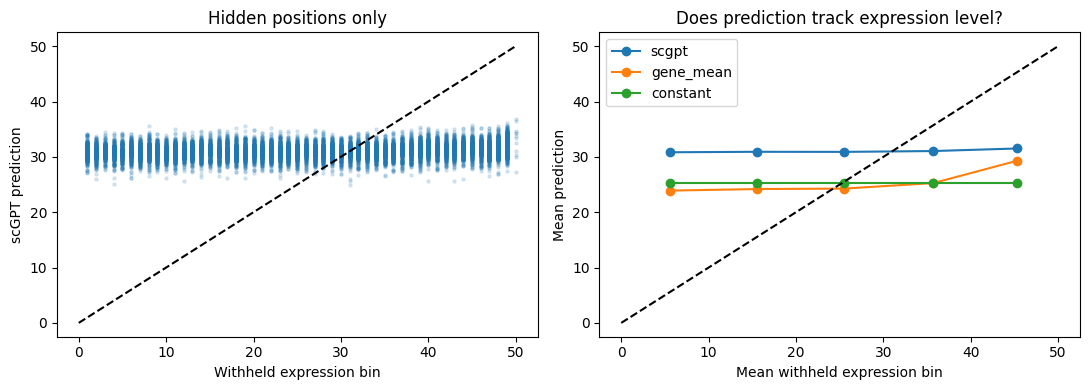

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(
    predictions["target_bin"],
    predictions["scgpt"],
    s=5,
    alpha=0.15,
)
axes[0].plot([0, 50], [0, 50], color="black", linestyle="--")
axes[0].set_xlabel("Withheld expression bin")
axes[0].set_ylabel("scGPT prediction")
axes[0].set_title("Hidden positions only")

binned_summary = (
    predictions.assign(
        expression_band=pd.cut(
            predictions["target_bin"],
            bins=[0, 10, 20, 30, 40, 50],
        )
    )
    .groupby("expression_band", observed=True)
    [["target_bin", "scgpt", "gene_mean", "constant"]]
    .mean()
)

for method in ["scgpt", "gene_mean", "constant"]:
    axes[1].plot(
        binned_summary["target_bin"],
        binned_summary[method],
        marker="o",
        label=method,
    )

axes[1].plot([0, 50], [0, 50], color="black", linestyle="--")
axes[1].set_xlabel("Mean withheld expression bin")
axes[1].set_ylabel("Mean prediction")
axes[1].set_title("Does prediction track expression level?")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Diagnostic for the LAST evaluated cell and masking repeat.
all_predictions = output["mlm_output"][0, 1:].detach().cpu().numpy()
input_bins = expression[0, 1:].cpu().numpy()
known = input_bins != MASK_VALUE

print("Visible-position MAE:",
      np.mean(np.abs(all_predictions[known] - input_bins[known])))

print("Hidden-position MAE:",
      np.mean(np.abs(all_predictions[hidden] - target_bins)))

print("Visible predictions: mean / standard deviation:",
      all_predictions[known].mean(),
      all_predictions[known].std())

print("Hidden predictions: mean / standard deviation:",
      all_predictions[hidden].mean(),
      all_predictions[hidden].std())

target_check = pd.DataFrame({
    "raw_count": values[hidden],
    "target_bin": target_bins,
})

display(
    target_check.groupby("raw_count")["target_bin"]
    .agg(["count", "min", "max", "std"])
    .head(10)
)

print("Fraction of targets with raw count 1:",
      (target_check["raw_count"] == 1).mean())

Visible-position MAE: 12.706061
Hidden-position MAE: 13.383607
Visible predictions: mean / standard deviation: 30.198761 1.749873
Hidden predictions: mean / standard deviation: 30.94916 1.6239592


,count,min,max,std
raw_count,,,,
1.0,117,1.0,36.0,10.195554
2.0,38,37.0,44.0,2.137020
3.0,16,45.0,47.0,0.834166
4.0,3,48.0,48.0,0.000000
5.0,2,49.0,49.0,0.000000
6.0,1,49.0,49.0,NaN
7.0,1,49.0,49.0,NaN
13.0,1,49.0,49.0,NaN
24.0,1,50.0,50.0,NaN


Fraction of targets with raw count 1: 0.65


In [ ]:
# Preserve the last cell's original masked input.
original_input = expression.clone()

# Diagnostic only: reveal the hidden targets.
fully_visible = original_input.clone()
fully_visible[0, hidden + 1] = torch.as_tensor(
    target_bins, dtype=fully_visible.dtype
)

# Keep hidden positions masked, but shuffle visible values across genes.
shuffled_visible = original_input.clone()
visible_positions = np.flatnonzero(
    original_input[0, 1:].numpy() != MASK_VALUE
) + 1

shuffle_rng = np.random.default_rng(123)
permuted_positions = shuffle_rng.permutation(visible_positions)

shuffled_visible[0, visible_positions] = (
    original_input[0, permuted_positions]
)

conditions = {
    "original_masked": original_input,
    "fully_visible": fully_visible,
    "shuffled_visible": shuffled_visible,
}

diagnostic_predictions = {}
rows = []

with torch.inference_mode():
    for name, input_expression in conditions.items():
        result = model(
            tokens,
            input_expression,
            src_key_padding_mask=padding_mask,
            CLS=False,
            MVC=False,
            do_sample=False,
        )

        p = result["mlm_output"][0, hidden + 1].cpu().numpy()
        diagnostic_predictions[name] = p

        rows.append({
            "condition": name,
            "hidden_position_MAE": np.mean(np.abs(p - target_bins)),
            "prediction_mean": p.mean(),
            "prediction_std": p.std(),
        })

display(pd.DataFrame(rows))

original_p = diagnostic_predictions["original_masked"]

for name in ["fully_visible", "shuffled_visible"]:
    change = diagnostic_predictions[name] - original_p
    print(name, "RMS prediction change:",
          float(np.sqrt(np.mean(change ** 2))))

,condition,hidden_position_MAE,prediction_mean,prediction_std
0,original_masked,13.383607,30.949160,1.623959
1,fully_visible,12.861522,30.545120,1.721350
2,shuffled_visible,13.450540,31.369699,1.601435


fully_visible RMS prediction change: 1.3508977890014648
shuffled_visible RMS prediction change: 0.7141649723052979


In [ ]:
checkpoint = torch.load(
    MODEL_DIR / "best_model.pt",
    map_location="cpu",
)

if "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

checkpoint_keys = [
    key.removeprefix("module.")
    for key in checkpoint
]

special_keys = [
    key for key in checkpoint_keys
    if "flag_encoder" in key or "cross_attn" in key
]

print("Generative-specific checkpoint tensors:", len(special_keys))
for key in special_keys[:16]:
    print(key)

del checkpoint
gc.collect()

Generative-specific checkpoint tensors: 1
flag_encoder.weight


44

### Take 2

In [ ]:
import inspect
import torch
import scgpt

print("scGPT version:", scgpt.__version__)
print("Model class:", type(model).__name__)
print("Model source:", inspect.getfile(type(model)))
print("Forward signature:", inspect.signature(model.forward))

audit_loaded = torch.load(
    MODEL_DIR / "best_model.pt",
    map_location="cpu",
)

audit_state = audit_loaded
for wrapper in ["state_dict", "model_state_dict"]:
    if wrapper in audit_state:
        audit_state = audit_state[wrapper]
        break

print("\nTotal checkpoint entries:", len(audit_state))

print("\nFirst transformer layer:")
for key, value in audit_state.items():
    if "transformer_encoder.layers.0." in key:
        print(key, tuple(value.shape))

print("\nFlag and expression-decoder tensors:")
for key, value in audit_state.items():
    clean_key = key.removeprefix("module.")
    if clean_key.startswith(("flag_encoder.", "decoder.", "mvc_decoder.")):
        print(key, tuple(value.shape))

print("\nCheckpoint tensors absent from our instantiated model:")
audit_expected = model.state_dict()

for key, value in audit_state.items():
    mapped = key.removeprefix("module.").replace("Wqkv.", "in_proj_")
    if mapped not in audit_expected:
        print(key, tuple(value.shape))

del audit_state, audit_loaded

scGPT version: 0.2.4
Model class: TransformerModel
Model source: /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py
Forward signature: (src: torch.Tensor, values: torch.Tensor, src_key_padding_mask: torch.Tensor, batch_labels: Optional[torch.Tensor] = None, CLS: bool = False, CCE: bool = False, MVC: bool = False, ECS: bool = False, do_sample: bool = False) -> Mapping[str, torch.Tensor]

Total checkpoint entries: 163

First transformer layer:
transformer_encoder.layers.0.self_attn.Wqkv.weight (1536, 512)
transformer_encoder.layers.0.self_attn.Wqkv.bias (1536,)
transformer_encoder.layers.0.self_attn.out_proj.weight (512, 512)
transformer_encoder.layers.0.self_attn.out_proj.bias (512,)
transformer_encoder.layers.0.linear1.weight (512, 512)
transformer_encoder.layers.0.linear1.bias (512,)
transformer_encoder.layers.0.linear2.weight (512, 512)
transformer_encoder.layers.0.linear2.bias (512,)
transformer_encoder.layers.0.norm1.weight (512,)
transformer_encod

In [ ]:
import json
import torch
import numpy as np
import pandas as pd

from scgpt.model import TransformerModel
from scgpt.tokenizer import GeneVocab

with open(MODEL_DIR / "args.json") as f:
    mvc_config = json.load(f)

mvc_vocab = GeneVocab.from_file(MODEL_DIR / "vocab.json")
assert all(t in mvc_vocab for t in ["<pad>", "<cls>"])

mvc_model = TransformerModel(
    ntoken=len(mvc_vocab),
    d_model=mvc_config["embsize"],
    nhead=mvc_config["nheads"],
    d_hid=mvc_config["d_hid"],
    nlayers=mvc_config["nlayers"],
    nlayers_cls=mvc_config.get("n_layers_cls", 3),
    n_cls=1,
    vocab=mvc_vocab,
    dropout=mvc_config["dropout"],
    pad_token=mvc_config["pad_token"],
    pad_value=mvc_config["pad_value"],
    input_emb_style=mvc_config["input_emb_style"],
    cell_emb_style="cls",
    do_mvc=True,                  # This enables the trained MVC head.
    mvc_decoder_style="inner product",
    do_dab=False,
    use_batch_labels=False,
    domain_spec_batchnorm=False,
    explicit_zero_prob=False,
    use_fast_transformer=False,
    pre_norm=False,
)

# The checkpoint has no cell-type classifier, and we won't use one.
del mvc_model.cls_decoder

mvc_checkpoint = torch.load(
    MODEL_DIR / "best_model.pt",
    map_location="cpu",
)

for wrapper in ["state_dict", "model_state_dict"]:
    if wrapper in mvc_checkpoint:
        mvc_checkpoint = mvc_checkpoint[wrapper]
        break

mvc_state = {
    key.removeprefix("module.").replace("Wqkv.", "in_proj_"): value
    for key, value in mvc_checkpoint.items()
}

# Explicitly account for the unused generative-route flag.
unused_flag = mvc_state.pop("flag_encoder.weight")
assert tuple(unused_flag.shape) == (2, mvc_config["embsize"])

# No silent omissions or randomly initialized MVC weights.
mvc_model.load_state_dict(mvc_state, strict=True)
mvc_model.eval()
mvc_model.requires_grad_(False)

print("Strictly loaded tensors:", len(mvc_state))
print("Separately accounted-for tensor: flag_encoder.weight")
print("MVC decoder:", type(mvc_model.mvc_decoder).__name__)

del mvc_checkpoint, mvc_state, unused_flag

Strictly loaded tensors: 162
Separately accounted-for tensor: flag_encoder.weight
MVC decoder: MVCDecoder


In [ ]:
# original_input was saved by the previous sensitivity diagnostic.
known_positions = original_input[0].ne(MASK_VALUE)

# Include <cls>; exclude every hidden gene from the encoder input.
assert known_positions[0].item()
known_tokens = tokens[:, known_positions]
known_expression = original_input[:, known_positions]

target_positions = torch.as_tensor(hidden + 1, dtype=torch.long)
target_tokens = tokens.index_select(1, target_positions)

known_padding = torch.zeros_like(known_tokens, dtype=torch.bool)

assert not torch.any(known_expression == MASK_VALUE)
assert known_tokens.shape[1] + target_tokens.shape[1] == tokens.shape[1]

with torch.inference_mode():
    known_output = mvc_model(
        known_tokens,
        known_expression,
        src_key_padding_mask=known_padding,
        CLS=False,
        MVC=True,
        do_sample=False,
    )

    # Use the internal, unnormalized cell representation.
    cell_summary = known_output["cell_emb"]

    # Check that calling MVC directly reproduces its ordinary forward output.
    known_gene_embeddings = mvc_model.encoder(known_tokens)
    check = mvc_model.mvc_decoder(
        cell_summary, known_gene_embeddings
    )["pred"]

    torch.testing.assert_close(check, known_output["mvc_output"])

    # Query hidden genes using identity only—no expression input.
    target_gene_embeddings = mvc_model.encoder(target_tokens)
    mvc_prediction = mvc_model.mvc_decoder(
        cell_summary, target_gene_embeddings
    )["pred"][0].cpu().numpy()

assert np.isfinite(mvc_prediction).all()

comparison_predictions = {
    "previous_masked_decoder":
        diagnostic_predictions["original_masked"],
    "visible_only_MVC": mvc_prediction,
    "gene_mean": gene_baseline[cols[hidden]],
    "constant": np.full_like(target_bins, constant_baseline),
}

comparison_rows = []

for name, p in comparison_predictions.items():
    comparison_rows.append({
        "method": name,
        "MAE": np.mean(np.abs(p - target_bins)),
        "MSE": np.mean((p - target_bins) ** 2),
        "prediction_mean": np.mean(p),
        "prediction_std": np.std(p),
        "prediction_min": np.min(p),
        "prediction_max": np.max(p),
    })

display(pd.DataFrame(comparison_rows))

print("Visible context tokens, including <cls>:", known_tokens.shape[1])
print("Hidden genes queried:", target_tokens.shape[1])

,method,MAE,MSE,prediction_mean,prediction_std,prediction_min,prediction_max
0,previous_masked_decoder,13.383607,246.227081,30.949160,1.623959,25.667788,34.372929
1,visible_only_MVC,13.121901,220.188583,25.789116,3.411889,14.829131,36.305534
2,gene_mean,12.401349,202.825821,24.731206,6.053920,7.000000,44.521127
3,constant,13.192236,227.108597,25.299664,0.000000,25.299664,25.299664


Visible context tokens, including <cls>: 1020
Hidden genes queried: 180


In [ ]:
# Reconstruct the possible target-bin range for each hidden raw count.
hidden_counts = values[hidden]

left = np.digitize(hidden_counts, edges, right=False)
right = np.digitize(hidden_counts, edges, right=True)

# _digitize samples integers from right+1 through left when tied.
lower = np.where(left > right, right + 1, left)
lower = np.clip(lower, 1, N_BINS - 1)
upper = np.clip(left, 1, N_BINS - 1)

assert np.all(lower <= upper)

tie_mean = (lower + upper) / 2
tie_variance = ((upper - lower + 1) ** 2 - 1) / 12

tie_aware_rows = []

for name, p in comparison_predictions.items():
    p = np.asarray(p)

    # Expected squared error = error against tie mean + tie variance.
    expected_mse = np.mean((p - tie_mean) ** 2 + tie_variance)

    expected_mae = np.mean([
        np.abs(pred - np.arange(lo, hi + 1)).mean()
        for pred, lo, hi in zip(p, lower, upper)
    ])

    tie_aware_rows.append({
        "method": name,
        "expected_MAE": expected_mae,
        "expected_MSE": expected_mse,
        "MSE_against_tie_mean": np.mean((p - tie_mean) ** 2),
    })

display(pd.DataFrame(tie_aware_rows))

print("Average target variance from random tie-breaking:",
      tie_variance.mean())

,method,expected_MAE,expected_MSE,MSE_against_tie_mean
0,previous_masked_decoder,12.755783,225.536534,154.223108
1,visible_only_MVC,12.697305,212.330253,141.016827
2,gene_mean,12.291662,202.471210,131.157784
3,constant,12.906977,215.813806,144.500380


Average target variance from random tie-breaking: 71.31342592592593


In [ ]:
benchmark_rows = []

for cell_number, cell_index in enumerate(eval_indices, start=1):
    all_cols, all_values = positive_row(cell_index)

    cell_rng = np.random.default_rng(SEED + int(cell_index))
    chosen = np.sort(cell_rng.choice(
        len(all_cols),
        size=min(MAX_GENES, len(all_cols)),
        replace=False,
    ))

    cols = all_cols[chosen]
    values = all_values[chosen]

    for repeat in range(N_REPEATS):
        run_seed = SEED + 100000 * repeat + int(cell_index)
        mask_rng = np.random.default_rng(run_seed)

        n_hidden = max(1, int(round(MASK_FRACTION * len(cols))))
        hidden = np.sort(mask_rng.choice(
            len(cols), size=n_hidden, replace=False
        ))

        visible = np.ones(len(cols), dtype=bool)
        visible[hidden] = False

        edges = np.quantile(
            values[visible], np.linspace(0, 1, N_BINS - 1)
        )

        np.random.seed(run_seed)
        visible_bins = bin_with_edges(values[visible], edges)

        known_tokens = torch.tensor(
            [[mvc_vocab["<cls>"], *gene_tokens[cols[visible]].tolist()]],
            dtype=torch.long,
        )
        known_values = torch.tensor(
            [[PAD_VALUE, *visible_bins.tolist()]], dtype=torch.float32
        )
        query_tokens = torch.tensor(
            gene_tokens[cols[hidden]], dtype=torch.long
        ).unsqueeze(0)

        with torch.inference_mode():
            encoded = mvc_model(
                known_tokens,
                known_values,
                src_key_padding_mask=torch.zeros_like(
                    known_tokens, dtype=torch.bool
                ),
                CLS=False,
                MVC=False,
                do_sample=False,
            )

            mvc_p = mvc_model.mvc_decoder(
                encoded["cell_emb"],
                mvc_model.encoder(query_tokens),
            )["pred"][0].cpu().numpy()

        assert np.isfinite(mvc_p).all()

        # Expected target and variance under randomized tie-breaking.
        hidden_counts = values[hidden]
        left = np.digitize(hidden_counts, edges, right=False)
        right = np.digitize(hidden_counts, edges, right=True)

        lower = np.clip(
            np.where(left > right, right + 1, left), 1, N_BINS - 1
        )
        upper = np.clip(left, 1, N_BINS - 1)

        tie_mean = (lower + upper) / 2
        tie_var = ((upper - lower + 1) ** 2 - 1) / 12

        methods = {
            "MVC": mvc_p,
            "gene_mean": gene_baseline[cols[hidden]],
            "constant": np.full(len(hidden), constant_baseline),
        }

        for method, p in methods.items():
            benchmark_rows.append({
                "cell": adata.obs_names[cell_index],
                "copykat_group": groups[cell_index],
                "repeat": repeat,
                "method": method,
                "expected_MSE": np.mean((p - tie_mean)**2 + tie_var),
                "MSE_against_tie_mean": np.mean((p - tie_mean)**2),
                "prediction_std": np.std(p),
            })

    print(f"Completed {cell_number}/{len(eval_indices)}", flush=True)

benchmark = pd.DataFrame(benchmark_rows)

# Average repeats within each cell first.
cell_results = (
    benchmark.groupby(["cell", "copykat_group", "method"])[
        ["expected_MSE", "MSE_against_tie_mean", "prediction_std"]
    ].mean().reset_index()
)

display(
    cell_results.groupby(["copykat_group", "method"])
    .agg(
        n_cells=("cell", "nunique"),
        mean_expected_MSE=("expected_MSE", "mean"),
        median_expected_MSE=("expected_MSE", "median"),
        mean_prediction_std=("prediction_std", "mean"),
    )
)

paired = cell_results.pivot(
    index=["cell", "copykat_group"],
    columns="method",
    values="expected_MSE",
)

paired["MVC_minus_gene_mean"] = paired["MVC"] - paired["gene_mean"]

print("Cells where MVC beats gene mean:",
      int((paired["MVC_minus_gene_mean"] < 0).sum()), "/", len(paired))

display(
    paired.groupby(level="copykat_group")["MVC_minus_gene_mean"]
    .agg(["mean", "median", "min", "max"])
)

Completed 1/32
Completed 2/32
Completed 3/32
Completed 4/32
Completed 5/32
Completed 6/32
Completed 7/32
Completed 8/32
Completed 9/32
Completed 10/32
Completed 11/32
Completed 12/32
Completed 13/32
Completed 14/32
Completed 15/32
Completed 16/32
Completed 17/32
Completed 18/32
Completed 19/32
Completed 20/32
Completed 21/32
Completed 22/32
Completed 23/32
Completed 24/32
Completed 25/32
Completed 26/32
Completed 27/32
Completed 28/32
Completed 29/32
Completed 30/32
Completed 31/32
Completed 32/32


n_cells  mean_expected_MSE  median_expected_MSE  \
copykat_group method                                                       
aneuploid     MVC             16         192.593436           193.142717   
              constant        16         207.029267           205.320529   
              gene_mean       16         192.308285           191.425046   
diploid       MVC             16         188.396925           190.582875   
              constant        16         205.574530           205.101718   
              gene_mean       16         199.790434           199.473956   

                         mean_prediction_std  
copykat_group method                          
aneuploid     MVC               3.968271e+00  
              constant          3.552714e-15  
              gene_mean         6.315276e+00  
diploid       MVC               4.768829e+00  
              constant          2.886580e-15  
              gene_mean         5.879914e+00

Cells where MVC beats gene mean: 21 / 32


,mean,median,min,max
copykat_group,,,,
aneuploid,0.285151,2.755017,-15.047577,15.019659
diploid,-11.393509,-8.382896,-34.593226,0.879526
